In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("charts", exist_ok=True)


In [36]:
df=pd.read_csv("netflix_clean.csv",encoding="latin-1")

organize by release year

In [37]:
yearly=df.groupby("release_year").size().sort_index()

 Yearly content releases (focus on 2000 onward for a readable trend)

In [38]:
recent = yearly[yearly.index >= 2000]

Growth and decline

In [39]:
growth = recent.pct_change().mul(100).round(2)
trend = pd.DataFrame({"Titles": recent, "Growth %": growth})
print(trend.tail(12))
peak_year = recent.idxmax()
print(f"\nPeak year: {peak_year} with {recent.max()} titles")
print("Biggest growth year:", growth.idxmax(), f"({growth.max()}%)")
print("Biggest decline year:", growth.idxmin(), f"({growth.min()}%)")

              Titles  Growth %
release_year                  
2010             192     26.32
2011             185     -3.65
2012             236     27.57
2013             286     21.19
2014             352     23.08
2015             555     57.67
2016             901     62.34
2017            1030     14.32
2018            1146     11.26
2019            1030    -10.12
2020             953     -7.48
2021             592    -37.88

Peak year: 2018 with 1146 titles
Biggest growth year: 2016 (62.34%)
Biggest decline year: 2021 (-37.88%)


Trend visualizations

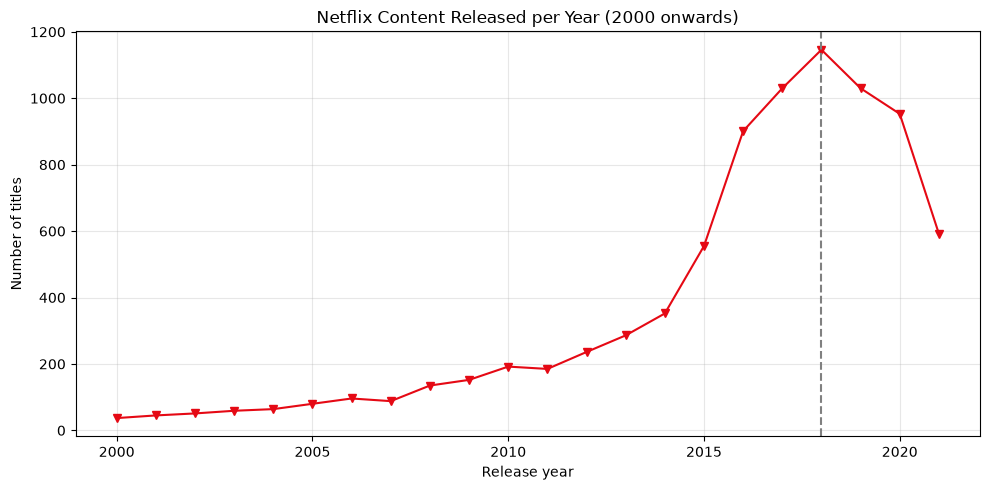

In [40]:
plt.figure(figsize=(10, 5))
plt.plot(recent.index, recent.values, marker="v", color="#E50914")
plt.axvline(peak_year, linestyle="--", color="grey")
plt.title("Netflix Content Released per Year (2000 onwards)")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("charts/task4_trend_per_year.png", dpi=150)
plt.show()

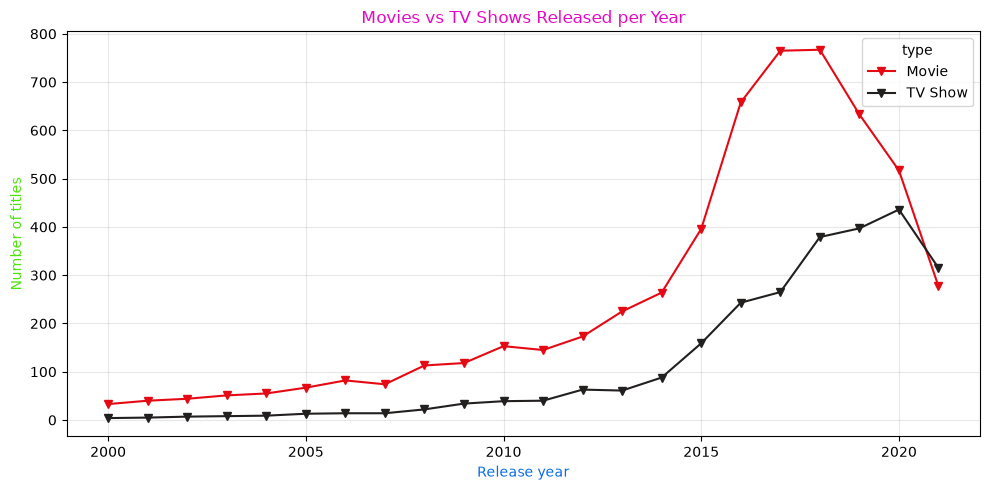

In [41]:
type_year = (df[df["release_year"] >= 2000]
             .groupby(["release_year", "type"]).size().unstack(fill_value=0))
type_year.plot(figsize=(10, 5), marker="v", color=["#E50914", "#221F1F"])
plt.title("Movies vs TV Shows Released per Year" , color="#E509C4")
plt.xlabel("Release year" , color="#096CE5")
plt.ylabel("Number of titles" , color="#4BE509")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("charts/task4_trend_by_type.png", dpi=150)
plt.show()

In [42]:
print(f"\nINSIGHTS: Content releases peaked in {peak_year}. "
      "Check the years after the peak: a drop usually reflects dataset cut-off "
      "(titles added to Netflix up to the data collection date) and slower production, "
      "so mention both in your report.")


INSIGHTS: Content releases peaked in 2018. Check the years after the peak: a drop usually reflects dataset cut-off (titles added to Netflix up to the data collection date) and slower production, so mention both in your report.
